In [9]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.impute import SimpleImputer

In [10]:
titanic = sns.load_dataset("titanic")

In [11]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [12]:
features = ["pclass", "sex" , "age", "embarked", "fare"]
target = ["survived"]

In [13]:
from sklearn.impute import SimpleImputer
imp_mean = SimpleImputer(strategy='mean')
titanic[["age"]] = imp_mean.fit_transform(titanic[["age"]])

imp_freq = SimpleImputer(strategy='most_frequent')
titanic[["embarked"]] = imp_freq.fit_transform(titanic[["embarked"]])

In [14]:
# encoding 
le = LabelEncoder()
titanic["sex"] = le.fit_transform(titanic["sex"])
titanic["embarked"] = le.fit_transform(titanic["embarked"])

In [23]:
X = titanic[features]
y = titanic["survived"]

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [25]:
model = DecisionTreeClassifier()
model.fit(X_train,y_train)

y_pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)

print("Accuracy scaore training = " , accuracy_score(y_train , y_pred_train)*100)
print("Accuracy scaore testing = " , accuracy_score(y_test , y_pred_test)*100)

Accuracy scaore training =  97.91332263242376
Accuracy scaore testing =  76.11940298507463


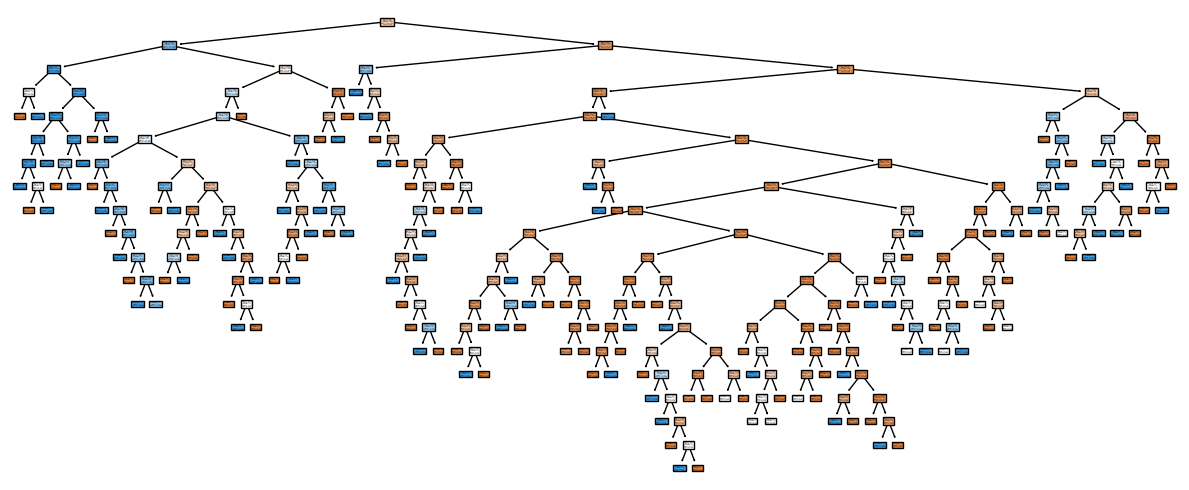

In [26]:
from sklearn.tree import plot_tree

plt.figure(figsize=(12 , 5))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Died" , "Survived"],
    filled=True,
)

plt.tight_layout()
plt.show()

# Random Forest Classifier

In [27]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
                n_estimators=201,
                oob_score=True,
                random_state=42
)

rf.fit(X_train , y_train)

y_pred = rf.predict(X_test)

print("OOB scaore = " , rf.oob_score_)
print("Accuracy scaore testing = " , accuracy_score(y_test , y_pred)*100)

OOB scaore =  0.8009630818619583
Accuracy scaore testing =  78.73134328358209


In [28]:
from sklearn.ensemble import BaggingClassifier
from sklearn.linear_model import LogisticRegression

base_model = LogisticRegression()

bagging = BaggingClassifier(
    base_model,
    n_estimators=201, 
)


bagging.fit(X_train , y_train)

y_pred = bagging.predict(X_test)

print("Accuracy is : " , accuracy_score(y_test , y_pred))

Accuracy is :  0.7947761194029851
